<a href="https://colab.research.google.com/github/fitraadhim/244107020089_MachineLearning/blob/main/JS06Regresi/tugasJS06Regresi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv('insurance.csv')

# Tampilkan 5 data teratas
print("5 Data Teratas:")
display(df.head())

# Informasi ringkas dataset
print("\nInformasi Dataset:")
df.info()

5 Data Teratas:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
# Cek missing values
print("Jumlah Missing Values:")
print(df.isnull().sum())

# Label Encoding untuk variabel kategorikal (sex, smoker, region)
le = LabelEncoder()
df['sex'] = le.fit_transform(df['sex'])       # female: 0, male: 1
df['smoker'] = le.fit_transform(df['smoker']) # no: 0, yes: 1
df['region'] = le.fit_transform(df['region']) # southeast, southwest, dll

# Identifikasi Variabel Bebas (Fitur) dan Variabel Target
# Fitur: age, sex, bmi, children, smoker, region
# Target: charges (biaya medis personal)
X = df.drop(columns=['charges'])
y = df['charges']

print("\nVariabel Fitur (X):")
print(X.head(2))
print("\nVariabel Target (y):")
print(y.head(2))

Jumlah Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Variabel Fitur (X):
   age  sex    bmi  children  smoker  region
0   19    0  27.90         0       1       3
1   18    1  33.77         1       0       2

Variabel Target (y):
0    16884.9240
1     1725.5523
Name: charges, dtype: float64


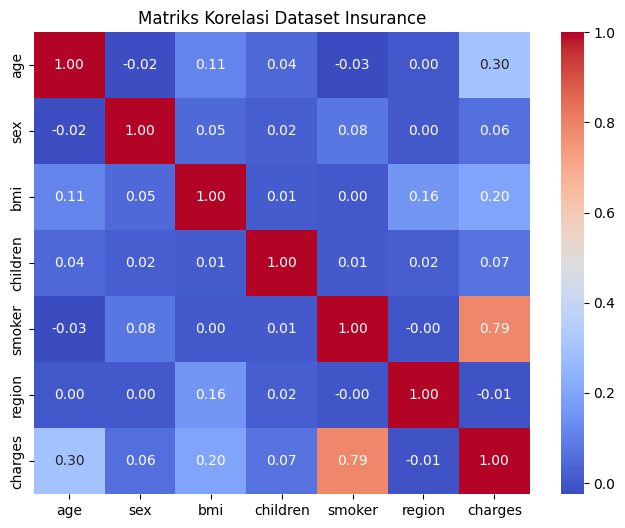

In [7]:
# Visualisasi Matriks Korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriks Korelasi Dataset Insurance")
plt.show()

In [8]:
# Bagi dataset menjadi Data Latih (Train) dan Data Uji (Test) dengan proporsi 80:20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah data latih: {X_train.shape[0]}")
print(f"Jumlah data uji: {X_test.shape[0]}")

# Lakukan Feature Scaling menggunakan StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Jumlah data latih: 1070
Jumlah data uji: 268


In [9]:
# Inisialisasi model Multiple Linear Regression
model = LinearRegression()

# Latih model pada data latih (yang sudah diskala)
model.fit(X_train_scaled, y_train)

# Lakukan prediksi pada data uji
y_pred = model.predict(X_test_scaled)

# Tampilkan koefisien regresi
print("Koefisien (Slope):", model.coef_)
print("Intercept:", model.intercept_)

Koefisien (Slope): [ 3.61610865e+03 -9.39295411e+00  2.02830858e+03  5.16662566e+02
  9.55714338e+03 -3.02387980e+02]
Intercept: 13346.089736364485


In [10]:
# Menghitung metrik evaluasi
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=== HASIL EVALUASI MODEL MULTIPLE LINEAR REGRESSION ===")
print(f"R-squared (R2 Score) : {r2:.4f}")
print(f"Mean Absolute Error  : {mae:.4f}")
print(f"Mean Squared Error   : {mse:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")

=== HASIL EVALUASI MODEL MULTIPLE LINEAR REGRESSION ===
R-squared (R2 Score) : 0.7833
Mean Absolute Error  : 4186.5089
Mean Squared Error   : 33635210.4312
Root Mean Squared Error: 5799.5871


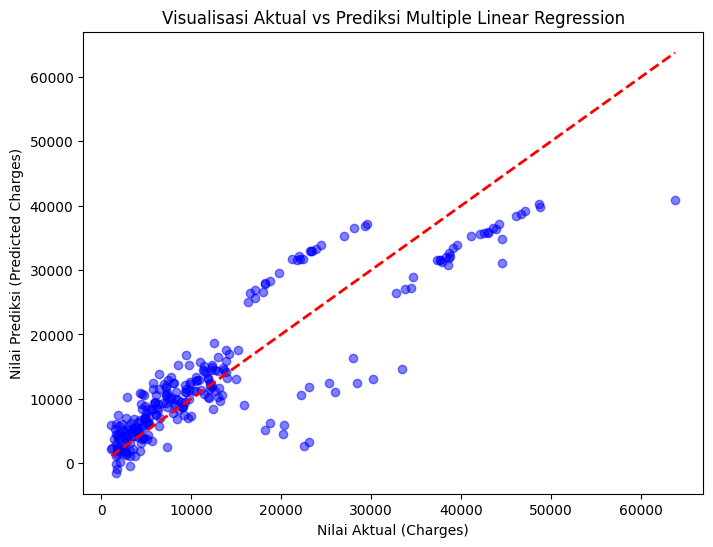

In [11]:
# Plot perbandingan nilai aktual vs prediksi
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, linestyle='--')
plt.xlabel("Nilai Aktual (Charges)")
plt.ylabel("Nilai Prediksi (Predicted Charges)")
plt.title("Visualisasi Aktual vs Prediksi Multiple Linear Regression")
plt.show()

## Analisis Hasil Tugas Praktikum: Multiple Linear Regression

Berdasarkan hasil eksekusi program pada dataset *Medical Cost Personal Datasets* (`insurance.csv`), berikut adalah analisis mendalam terhadap performa model dan evaluasi metrik yang diperoleh:

### 1. Evaluasi Performa Model
Berdasarkan hasil perhitungan metrik evaluasi pada data uji (*test set*), diperoleh nilai sebagai berikut:
* **R-squared ($R^2$) Score: 0.7833**  
  Nilai $R^2$ sebesar $0.7833$ (atau sekitar $78.33\%$) menunjukkan bahwa model *Multiple Linear Regression* yang dibangun mampu menjelaskan variasi biaya medis (*charges*) berdasarkan fitur-fitur masukan (seperti *age*, *bmi*, *smoker*, dll.) sebesar $78.33\%$. Sisanya sekitar $21.67\%$ dipengaruhi oleh faktor-faktor lain di luar model. Angka ini menandakan bahwa model memiliki tingkat kecocokan (*goodness of fit*) yang baik.
* **Mean Absolute Error (MAE): 4186.5089**  
  Rata-rata kesalahan mutlak dari prediksi model terhadap biaya medis aktual adalah sekitar `$4,186.51`.
* **Root Mean Squared Error (RMSE): 5799.5871**  
  Nilai RMSE menunjukkan penalti yang lebih besar terhadap kesalahan prediksi yang cukup signifikan. Mengingat skala biaya medis yang cukup bervariasi, angka ini mencerminkan deviasi rata-rata antara prediksi model dan nilai aslinya pada data uji.

### 2. Analisis Pengaruh Fitur (*Coefficients*)
Dari nilai koefisien (*slope*) yang dihasilkan oleh model regresi:
* **Status Merokok (*Smoker*):** Memiliki koefisien positif yang sangat tinggi (paling dominan) dibandingkan variabel lainnya. Hal ini mengindikasikan bahwa status perokok merupakan faktor pendorong utama yang sangat signifikan dalam menaikkan estimasi biaya medis seseorang.
* **BMI dan Usia (*Age*):** Berdasarkan koefisien positif dan matriks korelasi, peningkatan usia serta indeks massa tubuh (BMI) yang lebih tinggi juga berkontribusi secara linier terhadap naiknya biaya personal perawatan kesehatan.

### 3. Kesimpulan
Model *Multiple Linear Regression* berhasil dilatih dengan baik menggunakan pustaka Scikit-Learn dan *feature scaling* (`StandardScaler`). Visualisasi plot antara nilai aktual dan prediksi menunjukkan pola titik yang mendekati garis linear diagonal, yang membuktikan bahwa model mampu memprediksi tren biaya medis personal secara efektif meskipun terdapat beberapa variasi pencilan (*outliers*) pada data biaya tinggi.